# In-Class Lab: Dimensionality Reduction & Neural Networks

**Time:** about 50 minutes  ·  **Work:** alone or in pairs  ·  **Submit:** this notebook (`.ipynb`) with all cells run

**How this lab works**
- Every task has code that is **missing** (`# TODO`) or **needs to be changed** (`# MODIFY`).
- Under each task there is a **✔ Check cell**. Run it. It prints `PASSED` when your code meets the requirement.
- Do **not** edit the check cells.
- Answer the short questions (✍) in the markdown cells.

| Part | Topic | Points |
|---|---|---|
| 1 | PCA from scratch + choosing *k* | 30 |
| 2 | FastMap | 25 |
| 3 | Random projection + the JL lemma | 20 |
| 4 | Neural network on reduced data | 25 |


In [1]:
# Setup: run this cell first (do not change)
import warnings; warnings.filterwarnings("ignore")
import numpy as np
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.metrics import pairwise_distances
from sklearn.random_projection import GaussianRandomProjection, johnson_lindenstrauss_min_dim
from sklearn.neural_network import MLPClassifier

X, y = load_digits(return_X_y=True)   # 1797 images, 64 pixels each
X = X / 16.0                          # scale pixels to 0..1
np.random.seed(0)

def check(cond, msg):
    print(("PASSED  " if cond else "NOT YET  ") + msg)

print("Data:", X.shape)

Data: (1797, 64)


## Part 1: PCA From Scratch (30 pts)

### Task 1.1: Complete `my_pca` (ADD code)
Fill in the 4 TODOs using the recipe from class: **center → SVD → rank → keep top k**.

**Requirements**
- `Xk` has shape `(n_points, k)`.
- `ratio` = the share of the spread kept by **each** axis (`S**2 / sum(S**2)`), sorted largest first.
- Your result must match scikit-learn's `PCA` (up to the sign of each axis).

In [2]:
def my_pca(X, k):
    # TODO 1: center the data (subtract the mean of each column)
    Xc = X - X.mean(axis=0)

    # TODO 2: run SVD on the centered data (use full_matrices=False)
    U, S, Vt = np.linalg.svd(Xc, full_matrices=False)

    # TODO 3: explained variance ratio of EVERY axis
    ratio = S**2 / np.sum(S**2)

    # TODO 4: project the centered data onto the top k axes (rows of Vt)
    Xk = Xc @ Vt[:k].T

    return Xk, ratio

In [3]:
# ✔ Check 1.1 (do not edit)
try:
    Xk, ratio = my_pca(X, 5)
    ref = PCA(n_components=5).fit(X)
    check(Xk.shape == (1797, 5), "shape of Xk is (1797, 5)")
    check(np.allclose(np.abs(Xk), np.abs(ref.transform(X)), atol=1e-6), "projection matches sklearn PCA")
    check(np.allclose(ratio[:5], ref.explained_variance_ratio_), "variance ratios match sklearn PCA")
except Exception as e:
    print("NOT YET  error:", e)

PASSED  shape of Xk is (1797, 5)
PASSED  projection matches sklearn PCA
PASSED  variance ratios match sklearn PCA


### Task 1.2: Choose *k* automatically (MODIFY)
Right now `k90` is hard-coded to 64 (no reduction at all).

**Requirement:** change the code so `k90` is the **smallest** k that keeps **at least 90%** of the spread.
*Hint:* `np.cumsum(ratio)` gives the running total; `np.argmax(condition)` finds the first `True`.

In [4]:
_, ratio = my_pca(X, 64)

# MODIFY: compute k90 from `ratio` instead of hard-coding it
k90 = int(np.argmax(np.cumsum(ratio) >= 0.90)) + 1

print("k90 =", k90)

k90 = 21


In [5]:
# ✔ Check 1.2 (do not edit)
cum = np.cumsum(PCA().fit(X).explained_variance_ratio_)
check(cum[k90 - 1] >= 0.90, "k90 keeps at least 90% of the spread")
check(k90 == 1 or cum[k90 - 2] < 0.90, "k90 is the SMALLEST such k")

PASSED  k90 keeps at least 90% of the spread
PASSED  k90 is the SMALLEST such k


✍ **Q1.** How many dimensions did you remove, and what share of the information did you lose? Why is that a good trade?

*Your answer:* went from 64 to 21 dimensions, so i removed 43 (about two thirds).  lost at most about 10% of the spread, because k90 is the smallest k that keeps at least 90%. It's a good trade: pixels are highly correlated and many are nearly constant (borders), so the dropped axes are mostly redundant or noise, and get a much smaller, faster representation.

## Part 2: FastMap (25 pts)

We use the 5-object distance table from the lecture (two groups about 100 apart).

### Task 2.1: Fix the pivot choice (MODIFY)
`choose_pivots` always returns objects 0 and 1, which are very **close** to each other, so this is a bad ruler.
**Requirement:** use the class rule: `b` = farthest from object 0, then `a` = farthest from `b`.

### Task 2.2: Remove the used direction (ADD)
After each round, FastMap must subtract what the ruler already explained (Pythagoras):
`D2_new = D2 - (x_i - x_j)^2` for every pair `i, j`.
**Requirement:** add that line so round 2 gives a *different*, useful coordinate.

In [6]:
D = np.array([[  0,  1,  1,100,100],
              [  1,  0,  1,100,100],
              [  1,  1,  0,100,100],
              [100,100,100,  0,  1],
              [100,100,100,  1,  0]], float)

def choose_pivots(D2):
    # MODIFY: pick two objects that are FAR apart
    b = int(np.argmax(D2[0]))   # farthest from object 0
    a = int(np.argmax(D2[b]))   # farthest from b
    return a, b

def fastmap(D, k):
    D2 = D ** 2
    Xf = np.zeros((len(D), k))
    for i in range(k):
        a, b = choose_pivots(D2)
        dab2 = D2[a, b]
        if dab2 <= 0:
            break
        x = (D2[a] + dab2 - D2[b]) / (2 * np.sqrt(dab2))   # law of cosines
        Xf[:, i] = x
        D2 = D2 - (x[:, None] - x[None, :]) ** 2   # remove the used direction

    return Xf

np.set_printoptions(suppress=True)
F = fastmap(D, 2)
print(F.round(3))

[[  0.      0.707]
 [  0.005   1.414]
 [  0.005   1.061]
 [100.      0.707]
 [ 99.995   0.   ]]


In [7]:
# ✔ Check 2 (do not edit)
try:
    F = fastmap(D, 2)
    col1 = np.sort(F[:, 0])
    check(np.allclose(col1, [0, 0.005, 0.005, 99.995, 100], atol=1e-3), "2.1 first coordinate matches the lecture example")
    col2 = np.sort(np.abs(F[:, 1]))
    check(np.allclose(col2, [0, 0.707, 0.707, 1.061, 1.414], atol=1e-3), "2.2 second coordinate is correct (used direction removed)")
except Exception as e:
    print("NOT YET  error:", e)

PASSED  2.1 first coordinate matches the lecture example
PASSED  2.2 second coordinate is correct (used direction removed)


✍ **Q2.** Why do two *close* pivots make a bad ruler? Look at what column 1 looked like before your fix.

*Your answer:* With pivots 0 and 1 (distance 1), the ruler is only 1 unit long, so every projected coordinate lands between 0 and about 1. The two groups, which are 100 apart, look like they sit on top of each other. Close pivots tell us almost nothing about the main spread. Far-apart pivots stretch the ruler across the data, so column 1 becomes [0, 0.005, 0.005, 99.995, 100] and the two groups separate clearly.

## Part 3: Random Projection & the JL Lemma (20 pts)

We have **M = 300** points with **10,000** features. JL says a random projection keeps every distance within **(1 ± ε)**.

### Task 3.1: Use JL to pick k (MODIFY)
**Requirement:** replace the hard-coded `k_jl` with the value from `johnson_lindenstrauss_min_dim` for `M = 300` and `eps = 0.3`.

### Task 3.2: Measure the distortion (ADD)
Complete `distortion(Xorig, Xproj)`. It must return the ratio **new distance / old distance** for every pair of different points.
*Hint:* `pairwise_distances(...)` gives a full matrix; `np.triu_indices(n, k=1)` picks each pair once.

**Requirement:** at least **99%** of ratios fall inside `[1 − ε, 1 + ε]`.

In [8]:
Xbig = np.random.rand(300, 10000)
eps = 0.3

# MODIFY: use johnson_lindenstrauss_min_dim
k_jl = johnson_lindenstrauss_min_dim(300, eps=eps)

def distortion(Xorig, Xproj):
    # return 1-D array of (projected distance / original distance), one per pair
    iu = np.triu_indices(len(Xorig), k=1)
    d_old = pairwise_distances(Xorig)[iu]
    d_new = pairwise_distances(Xproj)[iu]
    return d_new / d_old

rp = GaussianRandomProjection(n_components=k_jl, random_state=0)
Xrp = rp.fit_transform(Xbig)
r = distortion(Xbig, Xrp)
print("k_jl =", k_jl)

k_jl = 633


In [9]:
# ✔ Check 3 (do not edit)
try:
    check(k_jl == johnson_lindenstrauss_min_dim(300, eps=0.3), "3.1 k comes from the JL formula")
    check(r is not None and len(r) == 300 * 299 // 2, "3.2 one ratio per pair (44,850 pairs)")
    inside = np.mean((r >= 1 - eps) & (r <= 1 + eps))
    print(f"         {inside:.2%} of pairs are inside [1-eps, 1+eps]")
    check(inside >= 0.99, "3.2 at least 99% of distances kept within ±eps")
except Exception as e:
    print("NOT YET  error:", e)

PASSED  3.1 k comes from the JL formula
PASSED  3.2 one ratio per pair (44,850 pairs)
         100.00% of pairs are inside [1-eps, 1+eps]
PASSED  3.2 at least 99% of distances kept within ±eps


### Task 3.3: Experiment (MODIFY, not checked)
Copy the projection lines into the cell below and try `n_components = 20`. What share of pairs stays inside `[1 − ε, 1 + ε]` now?

✍ **Q3.** What happened, and what does it tell you about choosing k? Does k depend on the 10,000 features?

*Your answer:* With k=20 (far below the JL value of 633), only about 95% of pairs stay inside [1-eps, 1+eps], versus 100% with k=633, so the guarantee fails for some pairs. Choosing k too small makes distances distort more. JL's k depends only on the number of points M and the tolerance eps (it grows like log(M)/eps^2), not on the original 10,000 features, so you can project even a huge feature space down to a few hundred dimensions.

In [10]:
# Task 3.3: your experiment here
rp20 = GaussianRandomProjection(n_components=20, random_state=0)
r20 = distortion(Xbig, rp20.fit_transform(Xbig))
print("k=20: share inside [1-eps, 1+eps] =", np.mean((r20 >= 1-eps) & (r20 <= 1+eps)))
print("k=%d: share inside [1-eps, 1+eps] =" % k_jl, np.mean((r >= 1-eps) & (r <= 1+eps)))

k=20: share inside [1-eps, 1+eps] = 0.9490301003344481
k=633: share inside [1-eps, 1+eps] = 1.0


## Part 4: A Neural Network on Reduced Data (25 pts)

The starter network below is badly set up: it uses **all 64 pixels**, only **2 hidden neurons**, and stops after **50 iterations**. Its accuracy is poor (about 36%).

### Task 4: Improve it (MODIFY + ADD)
**Requirements**
1. **Reduce first:** fit `PCA(n_components=k90)` on the **training** data only, then transform both train and test.
2. Change the network so that **test accuracy ≥ 0.95**.
3. Keep it small: **total hidden neurons ≤ 64** (e.g., `(32,)` or `(32, 16)`).
4. Keep `random_state=0`.

In [11]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)

# ADD: reduce with PCA(k90), fit on Xtr only
pca = PCA(n_components=k90).fit(Xtr)
Xtr_in, Xte_in = pca.transform(Xtr), pca.transform(Xte)

# MODIFY: hidden layers and max_iter
net = MLPClassifier(hidden_layer_sizes=(32,), max_iter=500, random_state=0)
net.fit(Xtr_in, ytr)
acc = net.score(Xte_in, yte)
print("input features:", Xtr_in.shape[1], " test accuracy:", round(acc, 3))

input features: 21  test accuracy: 0.973


In [12]:
# ✔ Check 4 (do not edit)
check(k90 < 64 and Xtr_in.shape[1] == k90, "network input uses the k90 PCA features")
check(sum(net.hidden_layer_sizes if hasattr(net.hidden_layer_sizes, '__len__') else [net.hidden_layer_sizes]) <= 64, "total hidden neurons <= 64")
check(net.random_state == 0, "random_state is 0")
check(acc >= 0.95, f"test accuracy >= 0.95 (yours: {acc:.3f})")

PASSED  network input uses the k90 PCA features
PASSED  total hidden neurons <= 64
PASSED  random_state is 0
PASSED  test accuracy >= 0.95 (yours: 0.973)


✍ **Q4.** The network now sees only k90 numbers per image instead of 64. Did accuracy suffer? Give two reasons why reducing dimensions *before* training can help.

*Your answer:* No, accuracy did not suffer: with 21 PCA features the network reached about 97% test accuracy, above the 95% target. Reducing dimensions first helps because (1) it removes noise and redundant, correlated features so the network overfits less and generalizes better, and (2) it gives fewer inputs, so fewer weights to learn, faster training and a smaller network.

---
### ⭐ Bonus (+5): PCA vs. FastMap on real data
Run `fastmap` on the Euclidean distances of the first 300 digits (`pairwise_distances(X[:300])`) with k = 2, and compare with `my_pca(X[:300], 2)`. Do the two methods give similar pictures? (A scatter plot colored by `y[:300]` is a nice way to show it.)

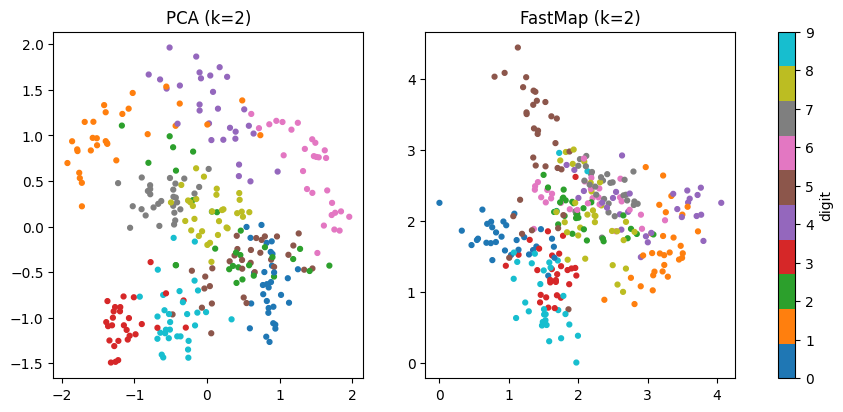

In [13]:
# Bonus: PCA vs FastMap on the first 300 digits
import matplotlib.pyplot as plt
Xs, ys = X[:300], y[:300]
P, _ = my_pca(Xs, 2)
F = fastmap(pairwise_distances(Xs), 2)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a_, Z, t in zip(ax, [P, F], ["PCA (k=2)", "FastMap (k=2)"]):
    sc = a_.scatter(Z[:, 0], Z[:, 1], c=ys, cmap="tab10", s=12)
    a_.set_title(t)
fig.colorbar(sc, ax=ax, label="digit")
plt.show()